# Calibrate Bruise Color — ปรับสีแผลฟกช้ำจากภาพถ่ายที่มีสเกลสี

สมุดงานใหม่สำหรับ `scale/Color_refercene_card.png` และรูปใน `Bruise_test_set` เท่านั้น ไม่ใช้ไฟล์ gradient เดิม

**วิธีใช้:** รันจากบนลงล่าง เลือกรูปหรือกดอัปโหลด แล้วกด `วิเคราะห์รูป` ได้เลย ไม่ต้องแก้โค้ดหรือเลือกกรอบ ระบบจับสเกล สีเนื้อ และบริเวณแผลอัตโนมัติ รองรับ JPG, PNG, WebP, BMP, TIFF, GIF, AVIF และ HEIC/HEIF (เมื่อมีตัวอ่าน)

`01.jpg` เป็นรูปสีเนื้อ **ไม่มีแผลฟกช้ำ**: notebook ต้องรายงานสีเนื้อ แต่ไม่สร้างเปอร์เซ็นต์สีแผลหรือเดาจำนวนวันจากรูปนี้

ขั้นหลักคือ **จับการ์ดในรูปถ่าย → fit color correction จากช่องการ์ด → ปรับสีทั้งภาพ → จับบริเวณแผล → เปรียบเทียบสีก่อน/หลัง calibration กับสเกล** ผล `ช่วงวันที่สอดคล้องกับสี` เป็นผลต่อยอดเชิงต้นแบบจากสีหลังปรับ พร้อมระดับความเชื่อมั่น ไม่ใช่อายุแผลที่ยืนยันได้ สีของแผลไม่สามารถบอกอายุแผลได้อย่างแม่นยำ การ์ด PDF/PNG เป็นสีไฟล์ต้นฉบับ ไม่ใช่ค่าสีที่ผ่านการรับรองของชิ้นงานพิมพ์จริง จึงต้องตรวจความคลาดสีของสเกลทุกภาพ

แหล่งข้อมูล: [Nuzzolese และ Di Vella, colorimetric bruise scale](https://pubmed.ncbi.nlm.nih.gov/23474503/); [systematic review ว่าการระบุอายุแผลจากสีไม่แม่น](https://pubmed.ncbi.nlm.nih.gov/15665179/)


## 1) Libraries and project settings

โหลดไลบรารี กำหนดโฟลเดอร์ รูปแบบไฟล์ที่รองรับ ฟอนต์ภาษาไทย และตัวเลือกการบันทึกผล ส่วนนี้เป็นจุดหลักสำหรับเปลี่ยนค่าของโปรเจกต์


In [1]:
from pathlib import Path
import io
import warnings
import cv2
from PIL import Image, ImageOps, UnidentifiedImageError
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.patches import Rectangle
from skimage.color import rgb2lab, lab2rgb, deltaE_ciede2000
from IPython.display import display, HTML
from html import escape
import ipywidgets as widgets
try:
    import pillow_heif
    pillow_heif.register_heif_opener()  # HEIC/HEIF หากติดตั้งไว้
except ImportError:
    pass

ROOT = Path.cwd()
if not (ROOT/'scale'/'Color_refercene_card.png').exists():
    ROOT = Path(r'D:\Supitsara\Documents\Senior Project\color_calibrate\Color_Calibrate-1')
PHOTO_DIR = ROOT / 'Bruise_test_set'
SCALE_FILE = ROOT / 'scale' / 'Color_refercene_card.png'
OUTPUT_DIR = ROOT / 'bruise_scale_outputs'
SAVE_RESULTS = False  # เปลี่ยนเป็น True เมื่อตรวจกรอบและ mask แล้ว
assert SCALE_FILE.exists(), f'ไม่พบการ์ดสี: {SCALE_FILE}'
PHOTO_DIR.mkdir(exist_ok=True)
IMAGE_SUFFIXES={'.jpg','.jpeg','.jpe','.jfif','.png','.webp','.bmp','.dib',
                '.tif','.tiff','.gif','.avif','.heic','.heif'}
def photo_names():
    return sorted(p.name for p in PHOTO_DIR.iterdir()
                  if p.is_file() and p.suffix.lower() in IMAGE_SUFFIXES)
for fp in [Path(r'C:\Windows\Fonts\tahoma.ttf'), Path(r'C:\Windows\Fonts\LeelawUI.ttf')]:
    if fp.exists():
        font_manager.fontManager.addfont(str(fp))
        plt.rcParams['font.family'] = font_manager.FontProperties(fname=str(fp)).get_name()
        plt.rcParams['axes.unicode_minus'] = False
        break
else:
    warnings.warn('ไม่พบฟอนต์ไทยบนเครื่อง กราฟอาจแสดงอักษรเป็นสี่เหลี่ยม')
print('พบรูป:', photo_names())


พบรูป: ['01.jpg', '02.jpg', '03.jpg', '04.jpg']


## 2) Image input and reference colors

อ่านภาพให้รองรับ JPG, PNG, WebP, TIFF, HEIC/HEIF และอ่านสีอ้างอิงจากไฟล์การ์ดดิจิทัล โดยไม่ใช้สีจากรูปถ่ายเป็น reference


In [2]:
def decode_rgb(payload,filename='รูปภาพ'):
    # Pillow reads the real file format, fixes phone EXIF rotation, and takes frame 1 of animations.
    try:
        with Image.open(io.BytesIO(payload)) as image:
            image.seek(0)
            image=ImageOps.exif_transpose(image)
            if image.mode in ('RGBA','LA') or 'transparency' in image.info:
                canvas=Image.new('RGBA',image.size,(255,255,255,255))
                canvas.alpha_composite(image.convert('RGBA'))
                image=canvas.convert('RGB')
            else:
                image=image.convert('RGB')
            return np.asarray(image).copy()
    except (UnidentifiedImageError,OSError,ValueError) as exc:
        raise ValueError(f'อ่านไฟล์ {filename} ไม่ได้: ต้องเป็นไฟล์ภาพจริง; HEIC/HEIF ต้องมี pillow-heif') from exc

def read_rgb(path):
    path=Path(path)
    return decode_rgb(path.read_bytes(),path.name)

def save_rgb(path, rgb):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    ok, data = cv2.imencode('.png', cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR))
    if not ok: raise ValueError('บันทึกภาพไม่ได้')
    data.tofile(str(path))

SCALE_RGB = read_rgb(SCALE_FILE)
SCALE_NAMES_SKIN = [f'สีเนื้อช่อง {i}' for i in range(1, 11)]
SCALE_NAMES_BRUISE = ['แดงเข้ม','น้ำเงินเข้ม','ม่วงอมชมพู','เขียวอมเหลือง','เหลืองอ่อน','น้ำตาลอมส้ม']
BRUISE_AGE_EXAMPLES = ['0–2 วัน','2–5 วัน','2–5 วัน','5–7 วัน','7–10 วัน','10–14 วัน']
# ช่วงนี้เป็นตัวอย่างเชิงประวัติศาสตร์ที่บทความยกมา ไม่ใช่โมเดลอายุที่ผ่านการตรวจสอบ
COLOUR_DAY_BANDS = {'แดงเข้ม':(0,2),'น้ำเงินเข้ม':(2,5),'ม่วงอมชมพู':(2,5),
                    'เขียวอมเหลือง':(5,7),'เหลืองอ่อน':(7,10),'น้ำตาลอมส้ม':(10,14)}

def reference_swatches(scale_rgb=SCALE_RGB):
    # พิกัดช่องในไฟล์การ์ด PNG 1890x1890: แถวบน 10 ช่อง, แถวล่าง 6 ช่อง
    h, w = scale_rgb.shape[:2]
    x0, x1 = 354*w/1890, 1537*w/1890
    rows = []
    for kind, n, y, names in [('skin',10,59*h/1890,SCALE_NAMES_SKIN),
                              ('bruise',6,176*h/1890,SCALE_NAMES_BRUISE)]:
        for i in range(n):
            x = x0 + (i+.5)*(x1-x0)/n
            xpix, ypix = int(round(x)), int(round(y))
            r = max(3, int((x1-x0)/n*.12))
            patch = scale_rgb[ypix-r:ypix+r+1, xpix-r:xpix+r+1]
            rgb = np.median(patch.reshape(-1,3), axis=0).astype(np.uint8)
            rows.append({'kind':kind,'index':i,'ชื่อสี':names[i],
                         'RGB':tuple(int(v) for v in rgb),
                         'HEX':'#%02X%02X%02X'%tuple(rgb)})
    return pd.DataFrame(rows)

REF = reference_swatches()
REF_RGB = np.asarray(REF['RGB'].tolist(), dtype=np.uint8)
REF_LAB = rgb2lab(REF_RGB[None,:,:]/255)[0]
COMMON_COLOURS=[
    ('ดำ',(20,20,20)),('เทาเข้ม',(65,65,65)),('เทา',(125,125,125)),('เทาอ่อน',(190,190,190)),
    ('น้ำตาลเข้ม',(78,52,46)),('น้ำตาล',(121,85,72)),('น้ำตาลแดง',(139,70,62)),
    ('น้ำตาลอมส้ม',(194,87,46)),('แดงเข้ม',(139,30,45)),('แดง',(198,40,40)),
    ('ม่วงเข้ม',(74,37,69)),('ม่วง',(106,61,112)),('ม่วงอมแดง',(126,63,91)),
    ('ม่วงอมชมพู',(181,109,140)),('ชมพู',(211,145,176)),('น้ำเงินเข้ม',(0,90,137)),
    ('เขียวเข้ม',(85,107,47)),('เขียวมะกอก',(128,128,64)),
    ('เขียวอมเหลือง',(187,168,105)),('เหลืองน้ำตาล',(184,155,84)),
    ('เหลืองอ่อน',(236,223,167)),('ส้ม',(210,105,46)),
    ('สีเนื้ออ่อน',(238,210,180)),('สีเนื้อกลาง',(205,160,115)),
    ('สีเนื้อเข้ม',(145,100,72))]
COMMON_LAB=rgb2lab(np.asarray([rgb for _,rgb in COMMON_COLOURS],np.uint8)[None,:,:]/255)[0]



### 2.1 Reference palette preview

ตรวจชื่อ สีจริง RGB และ HEX ของช่องสีเนื้อ 10 ช่องและช่องสีแผล 6 ช่อง


,kind,ชื่อสี,RGB,HEX
0,skin,สีเนื้อช่อง 1,"(244, 233, 223)",#F4E9DF
1,skin,สีเนื้อช่อง 2,"(241, 228, 214)",#F1E4D6
2,skin,สีเนื้อช่อง 3,"(246, 231, 207)",#F6E7CF
3,skin,สีเนื้อช่อง 4,"(236, 218, 189)",#ECDABD
4,skin,สีเนื้อช่อง 5,"(218, 193, 159)",#DAC19F
5,skin,สีเนื้อช่อง 6,"(173, 142, 103)",#AD8E67
6,skin,สีเนื้อช่อง 7,"(148, 113, 81)",#947151
7,skin,สีเนื้อช่อง 8,"(123, 90, 67)",#7B5A43
8,skin,สีเนื้อช่อง 9,"(95, 80, 68)",#5F5044
9,skin,สีเนื้อช่อง 10,"(79, 69, 60)",#4F453C


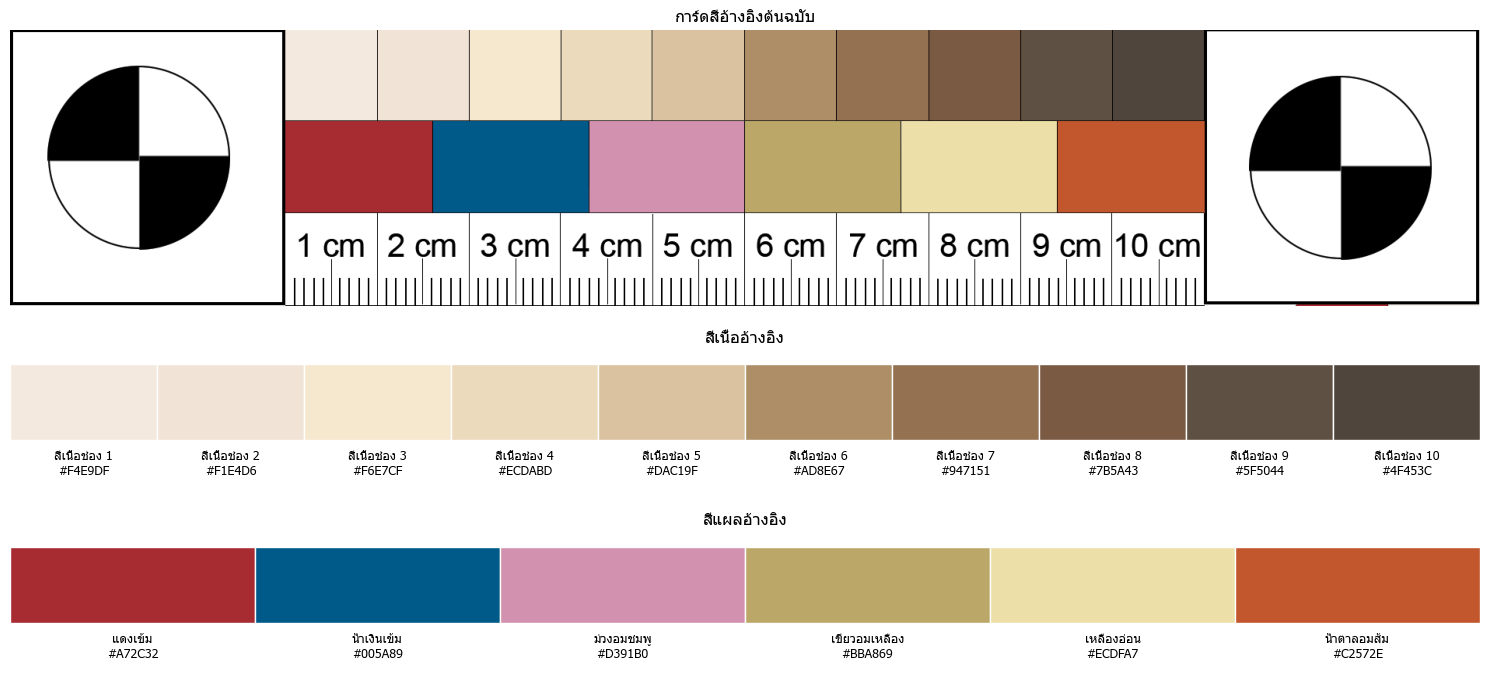

In [3]:
display(REF[['kind','ชื่อสี','RGB','HEX']])
fig,axes=plt.subplots(3,1,figsize=(15,7),gridspec_kw={'height_ratios':[2,1,1]})
axes[0].imshow(SCALE_RGB[:355,:]); axes[0].set_title('การ์ดสีอ้างอิงต้นฉบับ'); axes[0].axis('off')
for ax,kind,title in zip(axes[1:],['skin','bruise'],['สีเนื้ออ้างอิง','สีแผลอ้างอิง']):
    rows=REF[REF['kind']==kind].reset_index(drop=True)
    for i,row in rows.iterrows():
        ax.add_patch(Rectangle((i,0),1,1,facecolor=np.asarray(row['RGB'])/255,edgecolor='white'))
        ax.text(i+.5,-.12,f"{row['ชื่อสี']}\n{row['HEX']}",ha='center',va='top',fontsize=9)
    ax.set_xlim(0,len(rows)); ax.set_ylim(-.75,1.18); ax.set_title(title); ax.axis('off')
plt.tight_layout(); plt.show()


## 3) Scale geometry and color calibration

แปลงพิกัดแถบสี สร้างโมเดลปรับสี และตรวจโมเดลแบบ leave-one-out โมเดลต้องควบคุมความผิดพลาดของทุกช่องสีแผล ไม่ใช้ค่าเฉลี่ยเพียงอย่างเดียว


### 3.1 Scale coordinates and patch sampling


In [4]:
def parse_quad(value, shape):
    if not str(value).strip(): return None
    pts = []
    for pair in str(value).split(';'):
        xy = [float(v.strip()) for v in pair.split(',')]
        if len(xy)!=2: raise ValueError('กรอก 4 จุดเป็น x,y; x,y; x,y; x,y')
        pts.append(xy)
    if len(pts)!=4: raise ValueError('ต้องมี 4 จุดเรียง ซ้ายบน ขวาบน ขวาล่าง ซ้ายล่าง')
    arr = np.asarray(pts,np.float32)
    if not np.isfinite(arr).all() or (arr<0).any() or (arr>1).any():
        raise ValueError('พิกัดสเกลต้องอยู่ระหว่าง 0 ถึง 1')
    h,w = shape[:2]
    arr *= np.array([w-1,h-1],np.float32)
    if abs(cv2.contourArea(arr)) < 0.0003*w*h: raise ValueError('กรอบสเกลเล็กเกินไป')
    return arr

def extract_strip(photo, quad, n):
    if quad is None: return None
    width, height = n*100, 100
    dst = np.array([[0,0],[width-1,0],[width-1,height-1],[0,height-1]],np.float32)
    M = cv2.getPerspectiveTransform(quad.astype(np.float32),dst)
    strip = cv2.warpPerspective(photo,M,(width,height))
    patches = []
    for i in range(n):
        patch = strip[35:65, i*100+35:i*100+65]
        patches.append(np.median(patch.reshape(-1,3),axis=0).astype(np.uint8))
    return np.asarray(patches),strip

def srgb_to_linear(rgb):
    x=np.asarray(rgb,np.float64)/255
    return np.where(x<=.04045,x/12.92,((x+.055)/1.055)**2.4)

def linear_to_srgb(x):
    x=np.clip(np.asarray(x,np.float64),0,1)
    y=np.where(x<=.0031308,12.92*x,1.055*np.power(x,1/2.4)-.055)
    return np.rint(np.clip(y,0,1)*255).astype(np.uint8)

def fit_ccm(photo_patches, ref_patches, ridge=.5):
    X=np.column_stack([srgb_to_linear(photo_patches),np.ones(len(photo_patches))])
    Y=srgb_to_linear(ref_patches)
    anchor=np.zeros((4,3)); anchor[:3]=np.eye(3)
    reg=np.diag([ridge,ridge,ridge,ridge*4])
    weights=np.ones(len(X))
    for _ in range(8):
        A=(X.T*weights)@X+reg
        B=(X.T*weights)@Y+reg@anchor
        matrix=np.linalg.solve(A,B)
        residual=np.linalg.norm(X@matrix-Y,axis=1)
        scale=max(.01,float(np.median(residual))*1.7)
        weights=np.minimum(1,scale/np.maximum(residual,1e-6))
    return matrix

def fit_local_ccm(photo_patches,ref_patches,ridge=.2,sigma=.12,local_ridge=.1):
    # Smooth local corrections around measured card colours, after a global linear correction.
    base=fit_ccm(photo_patches,ref_patches,ridge=ridge)
    anchors=srgb_to_linear(photo_patches)
    X=np.column_stack([anchors,np.ones(len(anchors))])
    residual=srgb_to_linear(ref_patches)-X@base
    d2=np.sum((anchors[:,None,:]-anchors[None,:,:])**2,axis=2)
    kernel=np.exp(-d2/(2*sigma*sigma))
    coef=np.linalg.solve(kernel+local_ridge*np.eye(len(anchors)),residual)
    return {'base':base,'anchors':anchors,'coef':coef,'sigma':sigma}

def scale_ccm(model,strength):
    """Blend a fitted correction with identity so cross-validation can avoid over-correction."""
    identity=np.zeros((4,3)); identity[:3]=np.eye(3)
    if isinstance(model,dict):
        scaled=model.copy()
        scaled['base']=identity+strength*(model['base']-identity)
        scaled['coef']=strength*model['coef']
        return scaled
    return identity+strength*(model-identity)


In [5]:
def apply_ccm(rgb,matrix):
    if matrix is None: return rgb.copy()
    h,w=rgb.shape[:2]
    lin=srgb_to_linear(rgb).reshape(-1,3)
    if isinstance(matrix,dict):
        out=np.empty_like(lin)
        anchors=matrix['anchors']; coef=matrix['coef']; sigma=matrix['sigma']
        for start in range(0,len(lin),50000):
            part=lin[start:start+50000]
            base=part@matrix['base'][:3]+matrix['base'][3]
            d2=np.sum((part[:,None,:]-anchors[None,:,:])**2,axis=2)
            kernel=np.exp(-d2/(2*sigma*sigma))
            out[start:start+len(part)]=base+kernel@coef
        return linear_to_srgb(out.reshape(h,w,3))
    X=np.column_stack([lin,np.ones(len(lin))])
    return linear_to_srgb((X@matrix).reshape(h,w,3))

def ciede(rgb,ref_lab):
    pixels=np.asarray(rgb,np.uint8).reshape(-1,3)
    lab=rgb2lab(pixels[None,:,:]/255)[0]
    return np.column_stack([deltaE_ciede2000(lab,np.broadcast_to(r,lab.shape)) for r in ref_lab])


### 3.3 Model validation and selection


In [6]:
def calibration(photo,skin_quad_text,bruise_quad_text):
    strips=[]; obs=[]; tgt=[]; names=[]; kinds=[]
    for value,kind,n in [(skin_quad_text,'skin',10),(bruise_quad_text,'bruise',6)]:
        quad=parse_quad(value,photo.shape)
        out=extract_strip(photo,quad,n)
        if out is None: continue
        measured,strip=out
        strips.append((kind,quad,strip))
        ref=REF[REF.kind==kind]
        obs.extend(measured); tgt.extend(ref['RGB'].tolist()); names.extend(ref['ชื่อสี'])
        kinds.extend([kind]*n)
    if len(obs)<6: return None,{'status':'ไม่มีพิกัดสเกลที่ใช้ได้','strips':strips}
    obs=np.asarray(obs,np.uint8); tgt=np.asarray(tgt,np.uint8)
    # JPEG มักทำให้ช่องที่เกือบขาวมี median 252–254 แม้ยังเหลือข้อมูลสีอยู่
    # ตัดทิ้งเฉพาะ median ที่ชน 0/255 จริง เพื่อให้ช่องสีเนื้ออ่อนช่วยคุม highlight
    usable=(obs.min(axis=1)>3)&(obs.max(axis=1)<255)
    if usable.sum()<6: return None,{'status':'ช่องสเกลแสงล้นหรือมืดจนข้อมูลหาย','strips':strips}
    # Select correction strength by held-out swatches, with emphasis on bruise colors.
    idx=np.flatnonzero(usable)
    bruise_selector=np.asarray(kinds)=='bruise'
    target_lab=rgb2lab(tgt[None,:,:]/255)[0]
    raw_de=deltaE_ciede2000(rgb2lab(obs[None,:,:]/255)[0],target_lab)
    options=[]
    candidates=[('global',.5,None,0.0)]
    candidates += [('global',ridge,None,strength) for ridge in (.5,.2,.1)
                   for strength in (.25,.5,.75,1.0)]
    if usable.sum()>=8 and (usable&bruise_selector).sum()>=4:
        candidates += [('local',.2,(.12,.1),strength) for strength in (.25,.5,.75,1.0)]
    for kind,ridge,local_params,strength in candidates:
        held=[]
        for k in idx:
            train=usable.copy(); train[k]=False
            fold=(fit_local_ccm(obs[train],tgt[train],ridge=ridge,
                                sigma=local_params[0],local_ridge=local_params[1])
                  if kind=='local' else fit_ccm(obs[train],tgt[train],ridge=ridge))
            pred=apply_ccm(obs[k].reshape(1,1,3),scale_ccm(fold,strength)).reshape(1,3)
            held.append(float(ciede(pred,target_lab[k:k+1])[0,0]))
        held=np.asarray(held)
        bruise_held=held[bruise_selector[idx]]
        regression=np.maximum(held-raw_de[idx],0)
        objective=(np.median(held)+.15*np.median(bruise_held) if len(bruise_held)
                   else np.median(held))+.10*np.percentile(held,90)
        # ลงโทษโมเดลที่ทำให้สีซึ่งเดิมใกล้ reference อยู่แล้วแย่ลง
        objective+=.25*np.median(regression)+.10*np.percentile(regression,90)
        options.append((float(objective),kind,ridge,local_params,strength,held))
    # งานนี้เน้นสีแผล จึงเลือกเฉพาะโมเดลที่ไม่มีช่องสีแผลใดพลาดรุนแรงก่อน
    # แล้วจึงเลือกคะแนนรวมที่ดีที่สุด ป้องกัน median ดีแต่สีแผลบางช่องเพี้ยนมาก
    safe=[]
    for option in options:
        held=option[-1]
        bruise_held=held[bruise_selector[idx]]
        if len(bruise_held) and np.max(bruise_held)<=10:
            safe.append(option)
    pool=safe if safe else [option for option in options
                            if len(option[-1][bruise_selector[idx]]) and
                            np.max(option[-1][bruise_selector[idx]])<=12]
    if not pool: pool=options
    _,selected_kind,selected_ridge,selected_local,selected_strength,cv=min(
        pool,key=lambda entry:entry[0])
    fitted=(fit_local_ccm(obs[usable],tgt[usable],ridge=selected_ridge,
                         sigma=selected_local[0],local_ridge=selected_local[1])
           if selected_kind=='local' else fit_ccm(obs[usable],tgt[usable],ridge=selected_ridge))
    model=scale_ccm(fitted,selected_strength)
    cv_median=float(np.median(cv))
    bruise_cv=cv[bruise_selector[idx]]
    bruise_worst=float(bruise_cv.max()) if len(bruise_cv) else np.inf
    status=('พอใช้สำหรับต้นแบบ' if cv_median<=8 and bruise_worst<=10 else
            ('ควรตรวจแสง/พิกัดสเกล' if cv_median<=12 and bruise_worst<=15
             else 'ไม่ผ่าน: ห้ามตีความสีแผลหรือช่วงวัน'))
    corrected_patches=apply_ccm(obs.reshape(-1,1,3),model).reshape(-1,3)
    before_de=raw_de
    after_de=deltaE_ciede2000(rgb2lab(corrected_patches[None,:,:]/255)[0],target_lab)
    cv_by_patch=np.full(len(obs),np.nan); cv_by_patch[idx]=cv
    table=pd.DataFrame({'ประเภท':kinds,'ชื่อสี':names,'RGB ที่ถ่าย':[tuple(v) for v in obs],
                        'RGB หลังปรับ':[tuple(v) for v in corrected_patches],
                        'RGB ต้นฉบับ':[tuple(v) for v in tgt],
                        'ΔE00 ก่อน':before_de,'ΔE00 หลัง':after_de,
                        'ΔE00 ดีขึ้น':before_de-after_de,
                        'held-out ΔE00':cv_by_patch,'ใช้สร้างโมเดล':usable})
    return model,{'status':status,'LOOCV median ΔE00':cv_median,
                  'bruise LOOCV worst ΔE00':bruise_worst if np.isfinite(bruise_worst) else None,
                  'selection note':'จำกัดความคลาดเคลื่อนของช่องสีแผลไม่เกิน 10 ΔE00' if safe else 'ไม่พบโมเดลที่ทุกช่องสีแผลต่ำกว่า 10 ΔE00',
                  'selected ridge':selected_ridge,'method':selected_kind,
                  'correction strength':selected_strength,
                  'median ΔE00 before':float(np.median(before_de[usable])),
                  'median ΔE00 after':float(np.median(after_de[usable])),
                  'strips':strips,'table':table}


## 4) Color measurement and scale comparison

จัดกลุ่มสีที่พบจริงจากพิกเซล ตั้งชื่อสี คำนวณเปอร์เซ็นต์ และเทียบกับสเกลด้วย CIEDE2000 สีที่ห่างหรือกำกวมจะถูกรายงานว่าไม่ตรงสเกลแทนการบังคับเลือก


### 4.1 Pixel sampling utilities


In [7]:
def norm_box(x_range,y_range,shape):
    h,w=shape[:2]
    x0,x1=[int(round(v*w)) for v in x_range]
    y0,y1=[int(round(v*h)) for v in y_range]
    x0,x1=np.clip([x0,x1],0,w); y0,y1=np.clip([y0,y1],0,h)
    if x1-x0<20 or y1-y0<20: raise ValueError('กรอบเล็กเกินไป')
    return (x0,y0,x1,y1)

def paired_pixels(before,after,mask,max_pixels=35000):
    """Same locations before/after calibration for an honest comparison."""
    raw=before[mask]; fixed=after[mask]
    good=((raw.max(axis=1)>8)&(raw.max(axis=1)<251)&
          (fixed.max(axis=1)>8)&(fixed.max(axis=1)<251))
    raw,fixed=raw[good],fixed[good]
    if len(raw)>max_pixels:
        rng=np.random.default_rng(42); ids=rng.choice(len(raw),max_pixels,replace=False)
        raw,fixed=raw[ids],fixed[ids]
    if len(raw)<100: raise ValueError('บริเวณนี้ไม่มีพิกเซลก่อน/หลังที่ใช้ได้พอ')
    return raw,fixed

def sample_pixels(rgb,box,max_pixels=35000):
    x0,y0,x1,y1=box
    roi=rgb[y0:y1,x0:x1].reshape(-1,3)
    good=(roi.min(axis=1)>4)&(roi.max(axis=1)<251)
    roi=roi[good]
    if len(roi)>max_pixels:
        rng=np.random.default_rng(42); roi=roi[rng.choice(len(roi),max_pixels,replace=False)]
    if len(roi)<100: raise ValueError('บริเวณนี้ไม่มีพิกเซลที่ใช้ได้เพียงพอ')
    return roi

def colour_percentages(pixels,kind,max_de=None):
    ref=REF[REF.kind==kind].reset_index(drop=True)
    start=0 if kind=='skin' else 10
    distances=ciede(pixels,REF_LAB[start:start+len(ref)])
    label=distances.argmin(axis=1)
    nearest=distances.min(axis=1)
    ordered=np.partition(distances,1,axis=1)[:,:2]
    margin=ordered[:,1]-ordered[:,0]
    if max_de is None: max_de=14 if kind=='skin' else 15
    min_margin=.75 if kind=='skin' else 1.5
    # ถ้าห่างสเกลมากหรือสองสีใกล้กันเกินไป ให้รายงานว่าไม่แน่ใจแทนการบังคับชื่อสี
    label[(nearest>max_de)|(margin<min_margin)]=-1
    rows=[]
    for i,row in ref.iterrows():
        rows.append({'ชื่อสี':row['ชื่อสี'],'HEX':row['HEX'],
                     'เปอร์เซ็นต์':100*float(np.mean(label==i)),
                     'median ΔE00':float(np.median(nearest[label==i])) if np.any(label==i) else np.nan})
    rows.append({'ชื่อสี':'สีอื่น/ไม่ตรงช่องสเกล','HEX':'—',
                 'เปอร์เซ็นต์':100*float(np.mean(label==-1)),'median ΔE00':np.nan})
    return pd.DataFrame(rows).sort_values('เปอร์เซ็นต์',ascending=False).reset_index(drop=True)


In [8]:
def measured_colour_clusters(pixels,kind,max_clusters=None):
    """สรุปสีที่พบจริงจากภาพ ไม่บังคับให้พิกเซลเป็นสีของสเกลทันที"""
    pixels=np.asarray(pixels,np.uint8)
    if len(pixels)<100: return None
    rng=np.random.default_rng(42)
    sample=pixels[rng.choice(len(pixels),min(len(pixels),18000),replace=False)]
    sample_lab=rgb2lab(sample[None,:,:]/255)[0].astype(np.float32)
    # ตัดเฉพาะปลายสุดของแสง/เงา ลดโอกาสสร้างกลุ่มสีจากแสงสะท้อนหรือเงาดำ
    low,high=np.percentile(sample_lab[:,0],[2,98])
    keep=(sample_lab[:,0]>=low)&(sample_lab[:,0]<=high)
    sample=sample[keep]; sample_lab=sample_lab[keep]
    if len(sample_lab)<100: return None
    k=max_clusters or (3 if kind=='skin' else 4)
    k=max(1,min(k,len(sample_lab)//100))
    cv2.setRNGSeed(42)
    criteria=(cv2.TERM_CRITERIA_EPS+cv2.TERM_CRITERIA_MAX_ITER,80,.15)
    _,labels,centres=cv2.kmeans(sample_lab,k,None,criteria,8,cv2.KMEANS_PP_CENTERS)
    labels=labels.ravel(); counts=np.bincount(labels,minlength=k)
    ref=REF[REF.kind==kind].reset_index(drop=True)
    start=0 if kind=='skin' else 10
    rows=[]
    for cluster_id in np.argsort(counts)[::-1]:
        centre=centres[cluster_id]
        rgb=np.rint(np.clip(lab2rgb(centre[None,None,:])[0,0],0,1)*255).astype(np.uint8)
        distances=deltaE_ciede2000(centre[None,:],REF_LAB[start:start+len(ref)])
        nearest=int(np.argmin(distances)); de=float(distances[nearest])
        nearest_name=ref.iloc[nearest]['ชื่อสี']
        common_ids=[i for i,(name,_) in enumerate(COMMON_COLOURS)
                    if kind=='skin' or not name.startswith('สีเนื้อ')]
        common_distance=deltaE_ciede2000(centre[None,:],COMMON_LAB[common_ids])
        actual_name=COMMON_COLOURS[common_ids[int(np.argmin(common_distance))]][0]
        match=nearest_name if de<=15 else f'ไม่ตรงสเกล (ใกล้ {nearest_name})'
        rows.append({'ชื่อสีที่พบ':actual_name,'HEX':'#%02X%02X%02X'%tuple(rgb),
                     'RGB ที่พบ':tuple(int(v) for v in rgb),
                     'เปอร์เซ็นต์':100*float(counts[cluster_id]/counts.sum()),
                     'ผลเทียบสเกล':match,'ΔE00 ถึงสเกล':de})
    return pd.DataFrame(rows)

def palette_comparison(before,after,kind):
    a=colour_percentages(before,kind)
    b=colour_percentages(after,kind)
    table=a[['ชื่อสี','HEX','เปอร์เซ็นต์','median ΔE00']].merge(
        b[['ชื่อสี','เปอร์เซ็นต์','median ΔE00']],on='ชื่อสี',suffixes=(' ก่อน',' หลัง'))
    return table.sort_values('เปอร์เซ็นต์ หลัง',ascending=False).reset_index(drop=True)

def nearest_scale_distance(pixels,kind):
    start,n=(0,10) if kind=='skin' else (10,6)
    return float(np.median(ciede(pixels,REF_LAB[start:start+n]).min(axis=1)))


In [9]:
def estimate_colour_age(wound_table,cal_status,calibration_info=None):
    """ช่วงวันจากกลุ่มสีเด่นเพื่อใช้ในต้นแบบ ไม่ใช่อายุแผลทางคลินิก."""
    empty={'status':'ยังประเมินไม่ได้','ช่วงวัน':None,'ค่ากลางช่วง':None,
           'ความเชื่อมั่น':'ต่ำ','คะแนนความเชื่อมั่น':0,
           'หลักฐานสี':None,'เหตุผล':'ยังไม่มีสีแผล/สเกลที่ใช้ได้'}
    if wound_table is None: return empty
    if cal_status!='พอใช้สำหรับต้นแบบ':
        return {**empty,'เหตุผล':'คุณภาพ calibration ของสเกลไม่ผ่านเกณฑ์ต้นแบบ'}
    counts={name:float(wound_table.loc[wound_table['ชื่อสี']==name,'เปอร์เซ็นต์'].sum())
            for name in COLOUR_DAY_BANDS}
    coverage=sum(counts.values())
    if coverage<60: return {**empty,'เหตุผล':f'สีที่ตรง 6 ช่องสเกลมีเพียง {coverage:.1f}%'}
    dominant=max(counts,key=counts.get)
    held=np.nan
    if calibration_info is not None and 'table' in calibration_info:
        check=calibration_info['table']
        row=check.loc[check['ชื่อสี']==dominant]
        if len(row):
            held=float(row.iloc[0]['held-out ΔE00'])
            if not np.isfinite(held) or held>12:
                return {**empty,'เหตุผล':f'สีแผลเด่น {dominant} ยังไม่ผ่านการตรวจปรับเทียบรายสี (held-out ΔE00={held:.1f})'}
    groups={}
    for name,pct in counts.items():
        band=COLOUR_DAY_BANDS[name]
        groups[band]=groups.get(band,0.0)+pct
    ordered=sorted(groups.items(),key=lambda pair:pair[1],reverse=True)
    top_band,top_pct=ordered[0]
    evidence=pd.DataFrame([{'ช่วงวันตามสี':f'{lo}–{hi} วัน','สีรวมในกลุ่ม %':round(pct,1)}
                           for (lo,hi),pct in ordered])
    if top_pct<40:
        return {**empty,'หลักฐานสี':evidence,'เหตุผล':'ไม่มีกลุ่มสีเด่นอย่างน้อย 40%; สีหลายช่วงปะปนกัน'}
    relevant=[band for band,pct in ordered if pct>=15]
    lo=min(band[0] for band in relevant); hi=max(band[1] for band in relevant)
    if hi-lo>8:
        return {**empty,'หลักฐานสี':evidence,
                'เหตุผล':f'สีหลายช่วงขัดกัน ({lo}–{hi} วันตามตาราง); ไม่ควรให้ตัวเลขเดียว'}
    midpoint=(lo+hi)/2 if len(relevant)==1 and top_pct>=65 else None
    cv=float(calibration_info.get('LOOCV median ΔE00',15)) if calibration_info else 15
    colour_quality=max(0,1-min(cv,15)/15)
    patch_quality=max(0,1-min(held if np.isfinite(held) else 15,15)/15)
    evidence_strength=min(1,coverage/90)*.35+min(1,top_pct/70)*.35
    confidence_score=int(round(100*min(.65,evidence_strength+.15*colour_quality+.15*patch_quality)))
    confidence=('จำกัด — ใช้เป็นช่วงคัดกรองของต้นแบบเท่านั้น' if confidence_score>=50
                else 'ต่ำ — สีและภาพถ่ายยังไม่พอสำหรับระบุอายุแผล')
    reason=(f'กลุ่มสีเด่น {top_pct:.1f}% ของพิกเซลแผล; ไม่มีกลุ่มช่วงอื่น ≥15%'
            if len(relevant)==1 else
            f'กลุ่มสีเด่น {top_pct:.1f}% แต่มีสีกลุ่มช่วงอื่น ≥15% จึงขยายช่วง')
    return {'status':'ช่วงวันที่สอดคล้องกับสี (ต้นแบบ)','ช่วงวัน':f'{lo}–{hi} วัน',
            'ค่ากลางช่วง':midpoint,'ความเชื่อมั่น':confidence,
            'คะแนนความเชื่อมั่น':confidence_score,'หลักฐานสี':evidence,
            'เหตุผล':reason}


## 5) Bruise mask and size measurement

สร้าง mask แผลจากความต่างกับผิว ลด noise และคำนวณขนาดโดยใช้ไม้บรรทัดบนการ์ด


In [10]:
def wound_mask(corrected,wound_box,skin_pixels):
    x0,y0,x1,y1=wound_box
    roi=corrected[y0:y1,x0:x1]
    skin_lab=np.median(rgb2lab(skin_pixels[None,:,:]/255)[0],axis=0)
    lab=rgb2lab(roi/255)
    de=deltaE_ciede2000(lab,np.broadcast_to(skin_lab,lab.shape))
    chroma=np.linalg.norm(lab[...,1:]-skin_lab[1:],axis=2)
    darkness=skin_lab[0]-lab[...,0]
    exposure=(roi.max(axis=2)>8)&(roi.max(axis=2)<251)
    proposed=((de>=12)&((chroma>=8)|(darkness>=13)))&exposure
    mask=cv2.morphologyEx(proposed.astype(np.uint8),cv2.MORPH_OPEN,
                           cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(5,5)))
    mask=cv2.morphologyEx(mask,cv2.MORPH_CLOSE,
                          cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(9,9))).astype(bool)
    full=np.zeros(corrected.shape[:2],bool); full[y0:y1,x0:x1]=mask
    return full,float(mask.mean()),de

def estimate_wound_size(mask,calibration_info):
    # แถบแนวนอนบนการ์ดกว้าง 10 ซม. สูงราว 1 ซม. ต้องอยู่ระนาบใกล้ผิว
    strips=calibration_info.get('strips',[])
    preferred=[part for part in strips if part[0]=='bruise'] or strips
    if not preferred: return {'status':'ยังวัดไม่ได้: ไม่ได้ระบุตำแหน่งไม้บรรทัดบนการ์ด'}
    quad=preferred[0][1]
    # สร้างพิกัดเซนติเมตรด้วย affine transform จึงใช้การ์ดที่หมุนได้ด้วย
    dst=np.array([[0,0],[10,0],[0,1]],np.float32)
    affine=cv2.getAffineTransform(quad[[0,1,3]].astype(np.float32),dst)
    area_factor=abs(float(np.linalg.det(affine[:,:2])))
    if area_factor<=0 or not np.isfinite(area_factor):
        return {'status':'ยังวัดไม่ได้: พิกัดสเกลไม่ถูกต้อง'}
    n,labels,stats,_=cv2.connectedComponentsWithStats(mask.astype(np.uint8),8)
    if n<=1: return {'status':'ยังวัดไม่ได้: ไม่พบ mask แผล'}
    k=1+int(np.argmax(stats[1:,cv2.CC_STAT_AREA]))
    x,y,w,h,area=[int(v) for v in stats[k]]
    ys,xs=np.where(labels==k)
    points=np.column_stack([xs,ys]).astype(np.float32)
    if len(points)>50000: points=points[::int(np.ceil(len(points)/50000))]
    cm_points=points@affine[:,:2].T+affine[:,2]
    _,(side_a,side_b),_=cv2.minAreaRect(cm_points.astype(np.float32))
    short,long=sorted([float(side_a),float(side_b)])
    return {'status':'ประมาณจากรอยสีที่จับได้',
            'กว้าง ซม.':round(short,2),'ยาว ซม.':round(long,2),
            'พื้นที่ ซม.²':round(float(area*area_factor),2),
            'พิกเซลของรอยสี':area,
            'หมายเหตุ':'ค่าประมาณ: แผล/การ์ดต้องอยู่ระนาบใกล้กัน และกรอบกับ mask ต้องถูกตรวจด้วยตา'}



## 6) Manual analysis fallback

เส้นทางสำรองสำหรับกรณีที่ต้องระบุกรอบผิว แผล หรือพิกัดสเกลด้วยตนเอง โหมดปกติยังคงใช้การตรวจอัตโนมัติ


In [11]:
def analyse_photo(path,skin_box,wound_box=None,skin_quad='',bruise_quad=''):
    photo=read_rgb(path)
    matrix,cal=calibration(photo,skin_quad,bruise_quad)
    corrected=apply_ccm(photo,matrix)
    x0,y0,x1,y1=skin_box
    skin_area=np.zeros(photo.shape[:2],bool); skin_area[y0:y1,x0:x1]=True
    skin_before,skin_pixels=paired_pixels(photo,corrected,skin_area)
    skin_table=colour_percentages(skin_pixels,'skin')
    out={'path':Path(path),'original':photo,'corrected':corrected,'calibration':cal,
         'skin_box':skin_box,'skin_table':skin_table,'skin_pixels':skin_pixels,
         'skin_measured_colours':measured_colour_clusters(skin_pixels,'skin'),
         'skin_original_pixels':skin_before,
         'skin_comparison':palette_comparison(skin_before,skin_pixels,'skin'),
         'wound_box':wound_box,'wound_pixels':None,'wound_original_pixels':None,
         'wound_comparison':None,
         'wound_table':None,'wound_measured_colours':None,'wound_mask':None,'wound_fraction':0.0,
         'wound_size':{'status':'ยังวัดไม่ได้: ไม่มีภาพแผล'},
         'age_estimate':estimate_colour_age(None,cal['status'],cal),
         'age_note':'ไม่มีภาพแผลที่ให้วิเคราะห์ จึงยังประเมินไม่ได้',
         'skin_mask':None,'detection_note':'เลือกกรอบเอง'}
    if wound_box is not None:
        mask,fraction,_=wound_mask(corrected,wound_box,skin_pixels)
        out['wound_mask']=mask; out['wound_fraction']=fraction
        if mask.sum()>=200 and fraction>=.03:
            original_pixels,pixels=paired_pixels(photo,corrected,mask)
            out['wound_original_pixels']=original_pixels
            out['wound_pixels']=pixels
            out['wound_table']=colour_percentages(pixels,'bruise')
            out['wound_measured_colours']=measured_colour_clusters(pixels,'bruise')
            out['wound_comparison']=palette_comparison(original_pixels,pixels,'bruise')
            out['wound_size']=estimate_wound_size(mask,cal)
            out['age_estimate']=estimate_colour_age(out['wound_table'],cal['status'],cal)
            out['age_note']='สีแผลใช้เทียบช่วงวันแบบต้นแบบได้เมื่อผ่านเกณฑ์ แต่ไม่ใช่อายุแผลที่ยืนยันได้'
        else:
            out['wound_size']={'status':'ยังวัดไม่ได้: ไม่พบ mask แผลที่มากพอ'}
            out['age_note']='ไม่พบบริเวณสีแผลที่ต่างจากสีเนื้อเพียงพอ ตรวจกรอบและภาพก่อน; ยังประเมินไม่ได้'
    return out



## 7) Automatic reference-card detection

ค้นหาการ์ดจากลักษณะภาพหรือวงกลมสามจุด และตรวจแต่ละช่องสีก่อนยอมรับตำแหน่งสเกล


### 7.1 Three-marker fallback


In [12]:
def auto_find_card_markers(photo):
    # Fallback when ruler features repeat: locate the three printed checker-circle squares.
    h,w=photo.shape[:2]; resize=720/max(h,w)
    small=cv2.resize(photo,None,fx=resize,fy=resize)
    gray=cv2.cvtColor(small,cv2.COLOR_RGB2GRAY)
    template=cv2.cvtColor(SCALE_RGB[:355,:354],cv2.COLOR_RGB2GRAY)
    hits=[]
    for factor in (.18,.22,.26,.30,.34,.38):
        base=cv2.resize(template,None,fx=factor,fy=factor)
        for turn in range(4):
            target=np.rot90(base,turn).copy()
            correlation=cv2.matchTemplate(gray,target,cv2.TM_CCOEFF_NORMED)
            for _ in range(4):
                _,score,_,xy=cv2.minMaxLoc(correlation)
                if score>.58:
                    center=(np.asarray(xy,np.float32)+target.shape[0]/2)/resize
                    hits.append((float(score),center,float(target.shape[0]/resize)))
                cv2.rectangle(correlation,(xy[0]-30,xy[1]-30),
                              (xy[0]+30,xy[1]+30),-1,-1)
    unique=[]
    for hit in sorted(hits,key=lambda row:row[0],reverse=True):
        if all(np.linalg.norm(hit[1]-old[1])>max(20/resize,.30*hit[2]) for old in unique):
            unique.append(hit)
    if len(unique)<3: return None,'ไม่พบวงกลมมุมการ์ดครบ 3 จุด'
    source=np.float32([[177,177],[1713,177],[1713,1713]])
    choices=[]
    from itertools import permutations
    for tl,tr,br in permutations(unique[:5],3):
        across=tl[1]-tr[1]; down=br[1]-tr[1]
        if min(np.linalg.norm(across),np.linalg.norm(down))<2.5*max(tl[2],tr[2]): continue
        orth=abs(np.dot(across,down))/(np.linalg.norm(across)*np.linalg.norm(down))
        if orth>.42 or not .65<tl[2]/tr[2]<1.5: continue
        base=cv2.getAffineTransform(source,np.float32([tl[1],tr[1],br[1]]))
        H=np.vstack([base,[0,0,1]])
        axis=H[:2,1]; axis=axis/max(1e-6,np.linalg.norm(axis))
        for offset in (0,.05,.10,.15,.20):
            trial=H.copy(); trial[:2,2]+=axis*offset*np.median([tl[2],tr[2]])
            quads=[]; observed=[]
            for y0,y1,n in ((0,118,10),(118,235,6)):
                q=cv2.perspectiveTransform(
                    np.float32([[354,y0],[1537,y0],[1537,y1],[354,y1]]).reshape(-1,1,2),trial).reshape(-1,2)
                if ((q[:,0]<0)|(q[:,0]>=w)|(q[:,1]<0)|(q[:,1]>=h)).any(): break
                patch,_=extract_strip(photo,q,n); observed.extend(patch)
                quads.append('; '.join(f'{x/(w-1):.5f},{y/(h-1):.5f}' for x,y in q))
            if len(quads)!=2: continue
            raw=np.asarray(observed,np.uint8)
            raw_de=deltaE_ciede2000(rgb2lab(raw[None,:,:]/255)[0],REF_LAB)
            if np.median(raw_de)>18: continue
            try: _,check=calibration(photo,*quads)
            except (ValueError,np.linalg.LinAlgError): continue
            cv_error=check.get('LOOCV median ΔE00',np.inf)
            bruise_worst=check.get('bruise LOOCV worst ΔE00',np.inf)
            # median อย่างเดียวอาจซ่อนพิกัดผิดหนึ่งช่อง โดยเฉพาะช่องสีส้มปลายแถบ
            if (not np.isfinite(cv_error) or cv_error>12 or
                    not np.isfinite(bruise_worst) or bruise_worst>15): continue
            choices.append({'H':trial,'skin_quad':quads[0],'bruise_quad':quads[1],
                            'inliers':3,'cv_de':float(cv_error),
                            'bruise_worst':float(bruise_worst),
                            'score':float(cv_error)+.30*float(bruise_worst)+
                                    .12*float(np.median(raw_de)),
                            'marker_score':min(tl[0],tr[0],br[0])})
    if not choices: return None,'พบวงกลมการ์ด แต่ช่องสีไม่ผ่านการตรวจพิกัด/แสง'
    best=min(choices,key=lambda row:row['score'])
    return best,(f"จับสเกลจากวงกลม 3 จุด, median ΔE00={best['cv_de']:.1f}, "
                 f"สีแผลแย่สุด={best['bruise_worst']:.1f}")


### 7.2 Feature-based card detection


In [13]:
def auto_find_card(photo):
    """Find the printed L-card using ruler/circle features, not old images."""
    if not hasattr(cv2,'SIFT_create'):
        return auto_find_card_markers(photo)
    ref=SCALE_RGB[:355,:1537]
    sift=cv2.SIFT_create(nfeatures=6000)
    rk,rd=sift.detectAndCompute(cv2.cvtColor(ref,cv2.COLOR_RGB2GRAY),None)
    pk,pd=sift.detectAndCompute(cv2.cvtColor(photo,cv2.COLOR_RGB2GRAY),None)
    if rd is None or pd is None: return auto_find_card_markers(photo)
    pairs=cv2.BFMatcher().knnMatch(rd,pd,k=2)
    h,w=photo.shape[:2]; choices=[]
    for ratio in (.65,.70):
        good=[m for m,n in pairs if m.distance<ratio*n.distance]
        for subset in ('all','strip'):  # ตัด feature วงกลมซ้ายออกเมื่อช่วยให้ match ดีขึ้น
            kept=[m for m in good if subset=='all' or rk[m.queryIdx].pt[0]>354]
            if len(kept)<12: continue
            src=np.float32([rk[m.queryIdx].pt for m in kept])
            dst=np.float32([pk[m.trainIdx].pt for m in kept])
            H,inliers=cv2.findHomography(src,dst,cv2.RANSAC,4)
            if H is None or inliers is None or int(inliers.sum())<12: continue
            overall=cv2.perspectiveTransform(
                np.float32([[354,0],[1537,0],[1537,235],[354,235]]).reshape(-1,1,2),H).reshape(-1,2)
            if not np.isfinite(overall).all(): continue
            if (overall[:,0]<0).any() or (overall[:,0]>=w).any() or (overall[:,1]<0).any() or (overall[:,1]>=h).any(): continue
            area=abs(cv2.contourArea(overall.astype(np.float32)))/(w*h)
            if not .003<area<.25: continue
            long=np.mean([np.linalg.norm(overall[1]-overall[0]),np.linalg.norm(overall[2]-overall[3])])
            short=np.mean([np.linalg.norm(overall[3]-overall[0]),np.linalg.norm(overall[2]-overall[1])])
            if short<=0 or long/short<3: continue
            quads=[]
            for y0,y1 in [(0,118),(118,235)]:
                q=cv2.perspectiveTransform(
                    np.float32([[354,y0],[1537,y0],[1537,y1],[354,y1]]).reshape(-1,1,2),H).reshape(-1,2)
                quads.append('; '.join(f'{x/(w-1):.5f},{y/(h-1):.5f}' for x,y in q))
            try:
                _,check=calibration(photo,*quads)
            except (ValueError,np.linalg.LinAlgError): continue
            error=check.get('LOOCV median ΔE00',np.inf)
            if not np.isfinite(error) or error>15: continue
            choices.append({'H':H,'skin_quad':quads[0],'bruise_quad':quads[1],
                            'inliers':int(inliers.sum()),'cv_de':float(error),
                            'score':float(error)+15/max(1,int(inliers.sum()))})
    if not choices: return auto_find_card_markers(photo)
    best=min(choices,key=lambda x:x['score'])
    return best,f"จับสเกลอัตโนมัติ: {best['inliers']} จุดตรงกัน, ช่องทดสอบ ΔE00={best['cv_de']:.1f}"


## 8) Automatic skin and bruise detection

แยกผิวออกจากพื้นหลัง ตัดพื้นที่การ์ด ค้นหารอยสีที่ต่างจากผิวรอบข้าง และลดผลจากเงา แสงสะท้อน และ noise


### 8.1 Remove the printed card


In [14]:
def card_exclusion_mask(photo_shape, small_shape, card_H=None, marker_card=False):
    """Create a mask that prevents the printed card from being classified as skin or bruise."""
    h,w=photo_shape[:2]; sh,sw=small_shape[:2]
    excluded=np.zeros((sh,sw),np.uint8)
    if card_H is None: return excluded
    for polygon in ([[0,0],[1537,0],[1537,355],[0,355]],
                    [[1537,355],[1890,355],[1890,1890],[1537,1890]]):
        quad=cv2.perspectiveTransform(np.float32(polygon).reshape(-1,1,2),card_H).reshape(-1,2)
        quad*=np.array([sw/w,sh/h],np.float32)
        if np.isfinite(quad).all(): cv2.fillPoly(excluded,[quad.astype(np.int32)],255)
    # The vertical card arm may bend, so reserve the full strip below its top edge.
    top=cv2.perspectiveTransform(
        np.float32([[1537,355],[1890,355]]).reshape(-1,1,2),card_H).reshape(-1,2)
    if np.isfinite(top).all():
        margin=.01 if marker_card else .03
        left=max(0,int((min(top[:,0])-margin*w)*sw/w))
        right=min(sw,int((max(top[:,0])+.08*w)*sw/w))
        beginning=max(0,int((min(top[:,1])-.01*h)*sh/h))
        if right>left: cv2.rectangle(excluded,(left,beginning),(right,sh-1),255,-1)
    return cv2.dilate(excluded,cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(15,15)))

def skin_region_proposal(raw,excluded):
    """Find strict normal-skin seeds, the limb support area, and the final body mask."""
    sh,sw=raw.shape[:2]
    ycc=cv2.cvtColor(raw,cv2.COLOR_RGB2YCrCb)
    hsv=cv2.cvtColor(raw,cv2.COLOR_RGB2HSV)
    probable=((ycc[...,1]>=135)&(ycc[...,1]<=175)&
              (ycc[...,2]>=80)&(ycc[...,2]<=125)&(hsv[...,2]>70)&(excluded==0))
    probable=cv2.morphologyEx(probable.astype(np.uint8),cv2.MORPH_CLOSE,
                              cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(21,21)))
    count,labels,stats,_=cv2.connectedComponentsWithStats(probable,8)
    if count<=1: raise ValueError('ตรวจสีเนื้ออัตโนมัติไม่ได้: ผิวไม่แยกจากพื้นหลัง')
    component=1+int(np.argmax(stats[1:,cv2.CC_STAT_AREA]))
    if stats[component,cv2.CC_STAT_AREA]<.04*sw*sh:
        raise ValueError('พื้นที่สีเนื้อที่พบเล็กเกินไป: ลองภาพที่เห็นผิวชัดกว่า')
    skin=(labels==component).astype(np.uint8)
    skin_inner=cv2.erode(
        skin,cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(21,21))).astype(bool)
    skin_inner&=(excluded==0)
    contours,_=cv2.findContours(skin,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
    largest=max(contours,key=cv2.contourArea)
    support=np.zeros((sh,sw),np.uint8)
    cv2.fillConvexPoly(support,cv2.convexHull(largest),1)
    support=cv2.erode(
        support,cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(21,21))).astype(bool)
    support&=(excluded==0)
    if skin_inner.sum()<400: raise ValueError('พิกเซลผิวปกติไม่พอสำหรับเทียบสี')
    f=raw.astype(np.float32); R,G,B=f[...,0],f[...,1],f[...,2]
    warm=((R>1.07*G)&(G>1.04*B)&(R>70)&
          (ycc[...,1]>=133)&(ycc[...,1]<=190)&
          (ycc[...,2]>=75)&(ycc[...,2]<=140)&(excluded==0))
    warm=cv2.morphologyEx(warm.astype(np.uint8),cv2.MORPH_CLOSE,
                          cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(17,17)))
    wn,wl,ws,_=cv2.connectedComponentsWithStats(warm,8)
    overlap=np.bincount(wl[skin.astype(bool)],minlength=wn); overlap[0]=0
    main=int(np.argmax(overlap))
    body=wl==main if main>0 else skin.astype(bool)
    if main>0:
        x0,y0,bw0,bh0=ws[main,:4]
        for i in range(1,wn):
            if i==main or ws[i,cv2.CC_STAT_AREA]<.25*ws[main,cv2.CC_STAT_AREA]: continue
            xi,yi,bwi,bhi=ws[i,:4]
            gap=max(yi-(y0+bh0),y0-(yi+bhi),0)
            shared=max(0,min(x0+bw0,xi+bwi)-max(x0,xi))
            if gap<.18*sh and shared>.15*min(bw0,bwi): body|=wl==i
    body=cv2.morphologyEx(body.astype(np.uint8),cv2.MORPH_OPEN,
                          cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(21,21)))
    body=cv2.morphologyEx(body,cv2.MORPH_CLOSE,
                          cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(17,17))).astype(bool)
    body&=(excluded==0)
    if body.sum()<skin_inner.sum()*.7: body=skin_inner.copy()
    return skin_inner,support,body


### 8.3 Find and grow the bruise mask


In [15]:
def bruise_region_proposal(rgb,support,skin_inner,body,excluded):
    """Find a bruise seed, grow nearby changed colors, and fill safe internal gaps."""
    sh,sw=rgb.shape[:2]
    lab=rgb2lab(rgb/255)
    local=cv2.GaussianBlur(lab.astype(np.float32),(0,0),sigmaX=18)
    local_de=deltaE_ciede2000(lab,local)
    local_chroma=np.linalg.norm(lab[...,1:]-local[...,1:],axis=2)
    distances=ciede(rgb.reshape(-1,3),REF_LAB).reshape(sh,sw,16)
    skin_de=distances[...,:10].min(axis=2)
    bruise_de=distances[...,10:].min(axis=2)
    margin=skin_de-bruise_de
    normal_lab=np.median(lab[skin_inner],axis=0)
    relative_de=deltaE_ciede2000(lab,np.broadcast_to(normal_lab,lab.shape))
    purple_shift=((normal_lab[2]-lab[...,2]>10)&(lab[...,1]>8)&
                  (rgb[...,2]>=.83*rgb[...,1]))
    red_shift=((lab[...,1]-normal_lab[1]>14)&(lab[...,1]>25)&
               (rgb[...,2]>=.80*rgb[...,1]))
    skin_anomaly=(relative_de>18)&(normal_lab[0]-lab[...,0]>12)&(purple_shift|red_shift)
    exposure=(rgb.max(axis=2)>8)&(rgb.max(axis=2)<251)
    palette_match=((bruise_de<16)&
                   ((margin>7)|((margin>5)&(local_de>8)&(local_chroma>6))))
    candidate=support&exposure&(palette_match|skin_anomaly)
    candidate=cv2.morphologyEx(candidate.astype(np.uint8),cv2.MORPH_OPEN,
                               cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(5,5)))
    candidate=cv2.morphologyEx(candidate,cv2.MORPH_CLOSE,
                               cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(9,9)))
    n,parts,regions,_=cv2.connectedComponentsWithStats(candidate,8)
    lesion=np.zeros((sh,sw),bool)
    # Prefer a bruise-colour component. Reject very large areas and anything
    # touching the image edge, because those are usually floor/table shadows.
    small_min=max(40,int(support.sum()*.00015))
    fallback_min=max(150,int(support.sum()*.002))
    border=max(3,int(round(.01*min(sh,sw))))
    palette_choices=[]; anomaly_choices=[]
    for part_id in range(1,n):
        x,y,bw,bh,area=regions[part_id]
        if area<small_min or area>.12*support.sum(): continue
        if x<=border or y<=border or x+bw>=sw-border or y+bh>=sh-border: continue
        region=parts==part_id
        palette_pixels=int(np.count_nonzero(palette_match&region))
        palette_fraction=palette_pixels/max(1,int(area))
        anomaly_fraction=float(np.mean(skin_anomaly[region]))
        if palette_pixels>=20 and palette_fraction>=.12:
            palette_choices.append((palette_pixels,float(palette_fraction),int(area),part_id))
        elif area>=fallback_min and anomaly_fraction>=.50:
            anomaly_choices.append((int(area),float(anomaly_fraction),part_id))
    if palette_choices:
        k=max(palette_choices,key=lambda row:(row[0],row[1]))[3]
        lesion=parts==k
    elif anomaly_choices:
        k=max(anomaly_choices,key=lambda row:(row[0],row[1]))[2]
        lesion=parts==k
    if not lesion.any(): return lesion
    seed=lesion.copy()
    bw=regions[k,cv2.CC_STAT_WIDTH]; bh=regions[k,cv2.CC_STAT_HEIGHT]
    radius=max(24,min(36,int(round(.55*max(bw,bh)))))
    near=cv2.dilate(seed.astype(np.uint8),
        cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(2*radius+1,2*radius+1))).astype(bool)
    outer=cv2.dilate(seed.astype(np.uint8),
        cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(4*radius+1,4*radius+1))).astype(bool)
    ring=outer&~near&skin_inner
    normal=np.median(lab[ring],axis=0) if ring.sum()>=400 else normal_lab
    edge_de=deltaE_ciede2000(lab,np.broadcast_to(normal,lab.shape))
    edge_colour=((normal[1]-lab[...,1]>5)|(normal[2]-lab[...,2]>7)|(lab[...,1]-normal[1]>3))
    body_near=cv2.dilate(body.astype(np.uint8),
        cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(31,31))).astype(bool)
    grown=(near&body_near&(excluded==0)&(lab[...,1]>5)&
           (edge_de>5)&edge_colour)|seed
    grown=cv2.morphologyEx(grown.astype(np.uint8),cv2.MORPH_CLOSE,
                           cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(11,11)))
    total,parts,_,_=cv2.connectedComponentsWithStats(grown,8)
    core_overlap=np.bincount(parts[seed],minlength=total); core_overlap[0]=0
    lesion=parts==int(np.argmax(core_overlap))
    contours,_=cv2.findContours(lesion.astype(np.uint8),cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
    if not contours: return lesion
    filled=np.zeros((sh,sw),np.uint8)
    cv2.drawContours(filled,contours,-1,1,-1)
    main=max(contours,key=cv2.contourArea)
    hull=np.zeros((sh,sw),np.uint8)
    cv2.drawContours(hull,[cv2.convexHull(main)],-1,1,-1)
    if hull.sum()<=filled.sum()*1.25: filled=hull
    return filled.astype(bool)


### 8.4 Return full-resolution masks


In [16]:
def auto_skin_and_wound(photo,corrected,card_H=None,marker_card=False):
    """Run the automatic skin and bruise detector and return full-resolution masks."""
    h,w=photo.shape[:2]
    scale=720/max(h,w)
    sw,sh=max(40,round(w*scale)),max(40,round(h*scale))
    raw=cv2.resize(photo,(sw,sh)); rgb=cv2.resize(corrected,(sw,sh))
    excluded=card_exclusion_mask(photo.shape,raw.shape,card_H,marker_card)
    skin_inner,support,body=skin_region_proposal(raw,excluded)
    lesion=bruise_region_proposal(rgb,support,skin_inner,body,excluded)
    # Learn the person's normal skin colour beside the bruise, then extend
    # it across every connected skin section around the lesion. The colour
    # similarity and reference-card exclusions prevent a warm background from
    # being counted as skin.
    wound_guard=lesion.astype(bool)
    if lesion.any():
        ys,xs=np.where(lesion)
        lesion_span=max(int(xs.max()-xs.min()+1),int(ys.max()-ys.min()+1))
        sample_radius=max(55,min(150,int(round(1.35*lesion_span))))
        near=cv2.dilate(lesion.astype(np.uint8),
            cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(2*sample_radius+1,2*sample_radius+1))).astype(bool)
        seed=skin_inner&near&~cv2.dilate(lesion.astype(np.uint8),
            cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(31,31))).astype(bool)
        raw_lab=rgb2lab(raw/255)
        normal=np.median(raw_lab[seed],axis=0) if seed.sum()>=400 else np.median(raw_lab[skin_inner],axis=0)
        skin_de=deltaE_ciede2000(raw_lab,np.broadcast_to(normal,raw_lab.shape))
        grown_skin=body&~wound_guard&(excluded==0)&(skin_de<20)
        # A wider opening removes thin bridges to reflections on a table/floor.
        grown_skin=cv2.morphologyEx(grown_skin.astype(np.uint8),cv2.MORPH_OPEN,
            cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(31,31)))
        grown_skin=cv2.morphologyEx(grown_skin,cv2.MORPH_CLOSE,
            cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(21,21)))
        count,labels,stats,_=cv2.connectedComponentsWithStats(grown_skin,8)
        anchor=cv2.dilate(lesion.astype(np.uint8),
            cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(51,51))).astype(bool)&~wound_guard
        overlap=np.bincount(labels[anchor],minlength=count) if count>1 else np.zeros(count,dtype=int)
        if len(overlap): overlap[0]=0
        # Keep skin on every side of the bruise, not only the single largest side.
        components=np.where((overlap>=20)&(stats[:,cv2.CC_STAT_AREA]>=800))[0] if count>1 else np.array([],dtype=int)
        if len(components):
            skin_inner=np.isin(labels,components)
        else:
            skin_inner=body&near&~wound_guard
    else:
        skin_inner=skin_inner&~wound_guard
    skin_full=cv2.resize(skin_inner.astype(np.uint8),(w,h),interpolation=cv2.INTER_NEAREST).astype(bool)
    lesion_full=cv2.resize(lesion.astype(np.uint8),(w,h),interpolation=cv2.INTER_NEAREST).astype(bool)
    skin_before,skin_pixels=paired_pixels(photo,corrected,skin_full)
    x,y,bw,bh=cv2.boundingRect(np.column_stack(np.where(skin_inner)[::-1]).astype(np.int32))
    skin_box=(int(x*w/sw),int(y*h/sh),int((x+bw)*w/sw),int((y+bh)*h/sh))
    wound_box=None
    if lesion_full.any():
        ys,xs=np.where(lesion_full)
        wound_box=(int(xs.min()),int(ys.min()),int(xs.max()+1),int(ys.max()+1))
    return (skin_before,skin_pixels,skin_box,skin_full,lesion_full,wound_box,
            float(lesion.sum()/max(1,support.sum())))

def card_crop_box(shape,card,wound_box=None):
    """Crop to the visible L-card and wound, matching the close-up review view."""
    h,w=shape[:2]
    if not card or card.get('H') is None:
        return (0,0,w,h)
    # Outline of the printed L card in the 1890 x 1890 reference image.
    outline=np.float32([[0,0],[1890,0],[1890,1890],[1537,1890],
                        [1537,355],[0,355]])
    projected=cv2.perspectiveTransform(outline.reshape(-1,1,2),card['H']).reshape(-1,2)
    if not np.isfinite(projected).all():
        return (0,0,w,h)
    x0,y0=np.floor(projected.min(axis=0)).astype(int)
    x1,y1=np.ceil(projected.max(axis=0)).astype(int)
    if wound_box is not None:
        wx0,wy0,wx1,wy1=wound_box
        x0=min(x0,wx0); y0=min(y0,wy0); x1=max(x1,wx1); y1=max(y1,wy1)
    padding=max(8,int(round(.012*max(h,w))))
    x0=max(0,x0-padding); y0=max(0,y0-padding)
    x1=min(w,x1+padding); y1=min(h,y1+padding)
    if x1-x0<50 or y1-y0<50:
        return (0,0,w,h)
    return (x0,y0,x1,y1)


## 9) Complete automatic analysis pipeline

รวมการตรวจการ์ด การปรับสี การตรวจผิวและแผล การวัดสี และการวัดขนาดไว้ในขั้นตอนเดียว


In [17]:
def analyse_photo_auto(path):
    photo=read_rgb(path)
    card,card_note=auto_find_card(photo)
    skin_quad=card['skin_quad'] if card else ''
    bruise_quad=card['bruise_quad'] if card else ''
    matrix,cal=calibration(photo,skin_quad,bruise_quad)
    corrected=apply_ccm(photo,matrix)
    skin_before,skin_pixels,skin_box,skin_mask,lesion_mask,wound_box,fraction=auto_skin_and_wound(
        photo,corrected,card['H'] if card else None,
        bool(card and card['inliers']==3))
    out={'path':Path(path),'original':photo,'corrected':corrected,'calibration':cal,
         'skin_box':skin_box,'skin_mask':skin_mask,
         'skin_pixels':skin_pixels,'skin_original_pixels':skin_before,
         'skin_comparison':palette_comparison(skin_before,skin_pixels,'skin'),
         'skin_table':colour_percentages(skin_pixels,'skin'),
         'skin_measured_colours':measured_colour_clusters(skin_pixels,'skin'),
         'wound_box':wound_box,'wound_table':None,'wound_measured_colours':None,'wound_pixels':None,
         'wound_original_pixels':None,'wound_comparison':None,
         'wound_mask':lesion_mask,
         'wound_fraction':fraction,'wound_size':{'status':'ยังวัดไม่ได้: ไม่พบแผล'},
         'age_estimate':estimate_colour_age(None,cal['status'],cal),
         'age_note':'ยังไม่พบสีแผลที่ต่างจากสีเนื้ออย่างพอเพียง',
         'detection_note':card_note}
    out['crop_box']=card_crop_box(photo.shape,card,wound_box)
    if wound_box is not None:
        original_pixels,pixels=paired_pixels(photo,corrected,lesion_mask)
        out['wound_original_pixels']=original_pixels
        out['wound_pixels']=pixels
        out['wound_table']=colour_percentages(pixels,'bruise')
        out['wound_measured_colours']=measured_colour_clusters(pixels,'bruise')
        out['wound_comparison']=palette_comparison(original_pixels,pixels,'bruise')
        out['wound_size']=estimate_wound_size(lesion_mask,cal)
        out['age_estimate']=estimate_colour_age(out['wound_table'],cal['status'],cal)
        out['age_note']='ระบบเสนอ mask แผลอัตโนมัติ: ต้องตรวจ overlay ว่าจับแผลจริง ไม่ใช่เงา/สเกล'
    return out



## 10) Result tables, overlays, and histograms

แสดงช่องสีจริง ชื่อสี RGB, HEX, เปอร์เซ็นต์ ค่า ΔE00 ภาพ mask overlay ขนาดแผล และ RGB histograms โดยผลครั้งใหม่จะแทนผลเดิม


### 10.1 Color-swatch table


In [18]:
def display_colour_table(table):
    """แสดงตารางพร้อมช่องสีจริง ไม่ให้ผู้ใช้ต้องดูจากชื่อหรือรหัส HEX อย่างเดียว"""
    shown=table.copy()
    ref_hex=dict(zip(REF['ชื่อสี'],REF['HEX']))
    if 'HEX' not in shown.columns:
        name_pos=shown.columns.get_loc('ชื่อสี')+1 if 'ชื่อสี' in shown.columns else 0
        shown.insert(name_pos,'HEX',shown['ชื่อสี'].map(ref_hex).fillna('—'))
    shown.insert(0,'สีที่แสดง','')
    def text_value(value):
        if pd.isna(value) if np.isscalar(value) else False:
            return '—'
        if isinstance(value,(float,np.floating)):
            return f'{value:.2f}'
        return escape(str(value))
    head=''.join(f'<th>{escape(str(col))}</th>' for col in shown.columns)
    rows=[]
    for _,row in shown.iterrows():
        cells=[]
        for col in shown.columns:
            if col=='สีที่แสดง':
                hex_value=str(row.get('HEX','—'))
                if len(hex_value)==7 and hex_value.startswith('#'):
                    swatch=f'<span class="colour-swatch" style="background:{escape(hex_value)}"></span>'
                else:
                    swatch='<span class="colour-swatch unmatched"></span>'
                cells.append(f'<td class="swatch-cell">{swatch}</td>')
            else:
                cells.append(f'<td>{text_value(row[col])}</td>')
        rows.append('<tr>'+''.join(cells)+'</tr>')
    css=('table.colour-result{border-collapse:collapse;font-size:13px;margin:8px 0 18px 0}'
         'table.colour-result th{background:#24567e;color:white;padding:7px;border:1px solid #bbb}'
         'table.colour-result td{padding:6px 8px;border:1px solid #ccc;text-align:right}'
         'table.colour-result td:nth-child(2){text-align:left}'
         '.swatch-cell{text-align:center!important;min-width:92px}'
         '.colour-swatch{display:inline-block;width:76px;height:28px;border:1px solid #555;border-radius:3px}'
         '.unmatched{background:repeating-linear-gradient(135deg,#eee,#eee 6px,#aaa 6px,#aaa 12px)}')
    display(HTML(f'<style>{css}</style><table class="colour-result"><thead><tr>{head}</tr></thead>'
                 f'<tbody>{"".join(rows)}</tbody></table>'))

def show_calibration_summary(result):
    cal=result['calibration']
    print('รูป:',result['path'].name)
    print('การจับอัตโนมัติ:',result.get('detection_note','ไม่มีรายละเอียด'))
    print('ตรวจการ์ด:',cal['status'])
    if 'LOOCV median ΔE00' not in cal: return
    print('ความห่างสีช่องสเกลที่กันไว้ทดสอบ:',round(cal['LOOCV median ΔE00'],2),'ΔE00')
    print('วิธี calibration:', 'ปรับทั่วภาพ + แก้สีรายช่อง' if cal['method']=='local' else 'ปรับทั่วภาพ',
          '| ridge:',cal['selected ridge'],
          '| สัดส่วนการแก้สี:',f"{100*cal.get('correction strength',1):.0f}%")
    print('median ΔE00 ของช่องที่ใช้: ก่อน',f"{cal.get('median ΔE00 before',np.nan):.2f}",
          '→ หลัง',f"{cal.get('median ΔE00 after',np.nan):.2f}")
    print('เกณฑ์เลือกโมเดล:',cal.get('selection note','เลือกจาก held-out ΔE00'))
    worst=cal.get('bruise LOOCV worst ΔE00')
    if worst is not None and worst>12:
        print(f'เตือน: ช่องสีแผลบางช่องมี held-out ΔE00 สูงถึง {worst:.1f}; ดูตารางรายสีประกอบ')
    display_colour_table(cal['table'])


In [19]:
def show_colour_summary(result):
    cal=result['calibration']
    print('สีเนื้อที่พบจริงหลัง calibrate (จัดกลุ่มจากพิกเซลในภาพ)')
    if result.get('skin_measured_colours') is not None:
        display_colour_table(result['skin_measured_colours'])
    print('การเทียบสีเนื้อกับช่องสเกล: เปอร์เซ็นต์ก่อน → หลัง calibrate')
    skin=result['skin_comparison']
    skin=skin[(skin['เปอร์เซ็นต์ ก่อน']>=.5)|(skin['เปอร์เซ็นต์ หลัง']>=.5)]
    display_colour_table(skin.round(2))
    print('สีแผล:',result['age_note'])
    if result['wound_table'] is None: return
    print('รอยสีแผลคิดเป็น',round(100*result['wound_fraction'],1),
          '% ของผิวในพื้นที่ค้นหา — ต้องตรวจ mask ด้วยตา')
    print('สีแผลที่พบจริงหลัง calibrate (จัดกลุ่มจากพิกเซลใน mask)')
    if result.get('wound_measured_colours') is not None:
        display_colour_table(result['wound_measured_colours'])
    print('การเทียบสีแผลกับช่องสเกล: เปอร์เซ็นต์ก่อน → หลัง calibrate')
    wound=result['wound_comparison']
    wound=wound[(wound['เปอร์เซ็นต์ ก่อน']>=.5)|(wound['เปอร์เซ็นต์ หลัง']>=.5)]
    display_colour_table(wound.round(2))
    dominant=result['wound_table'].iloc[0]['ชื่อสี']
    if 'table' in cal and dominant in SCALE_NAMES_BRUISE:
        rows=cal['table'][cal['table']['ชื่อสี']==dominant]
        if len(rows) and np.isfinite(rows.iloc[0]['held-out ΔE00']):
            error=float(rows.iloc[0]['held-out ΔE00'])
            print(f'ช่องสเกลของสีแผลเด่น {dominant}: held-out ΔE00={error:.1f}')
            if error>12: print('เตือน: การปรับสีนี้ยังไม่แม่นสำหรับสีเด่น แม้สเกลโดยรวมผ่าน')
        elif len(rows):
            print('เตือน: ช่องสเกลของสีแผลเด่นถูกแสงล้น/มืดจนไม่ใช้ fit; ผลสีนี้ยังไม่ได้ตรวจ held-out')
    print('median ΔE00 ถึงช่องสีแผลที่ใกล้ที่สุด:',
          f"ก่อน {nearest_scale_distance(result['wound_original_pixels'],'bruise'):.2f}",
          f"หลัง {nearest_scale_distance(result['wound_pixels'],'bruise'):.2f}")
    print('หมายเหตุ: ΔE นี้คือความคล้ายช่องสเกล ไม่ใช่ค่าความผิดพลาดของสีแผลจริง')
    print('เปอร์เซ็นต์สีไม่ใช่โอกาสที่แผลมีอายุเท่านั้นวัน')

def show_size_and_age(result):
    print('ขนาดแผล:',result['wound_size']['status'])
    if 'กว้าง ซม.' in result['wound_size']:
        sz=result['wound_size']
        print(f"กว้าง × ยาว ≈ {sz['กว้าง ซม.']:.2f} × {sz['ยาว ซม.']:.2f} ซม.; "
              f"พื้นที่รอยสี ≈ {sz['พื้นที่ ซม.²']:.2f} ซม.²")
        print(sz['หมายเหตุ'])
    age=result['age_estimate']
    if age['ช่วงวัน'] is None:
        print('ช่วงวันที่สอดคล้องกับสี: ยังประเมินไม่ได้ —',age['เหตุผล'])
        return
    print('ช่วงวันที่สอดคล้องกับสี (ต้นแบบ):',age['ช่วงวัน'])
    print('ความเชื่อมั่น:',age['ความเชื่อมั่น'],f"({age['คะแนนความเชื่อมั่น']}/100)")
    if age['ค่ากลางช่วง'] is not None:
        print(f"ค่ากลางของช่วงเพื่อสรุป ≈ {age['ค่ากลางช่วง']:.1f} วัน (ไม่ใช่วันที่แผลเกิดจริง)")
    print('เหตุผล:',age['เหตุผล'])
    print('คำเตือน: ช่วงนี้เป็นความเข้ากันได้ของสี ไม่ใช่การยืนยันว่าแผลเกิดมาแล้วกี่วัน')
    if age['หลักฐานสี'] is not None: display(age['หลักฐานสี'])

def show_image_overlay(result):
    cal=result['calibration']
    fig,axes=plt.subplots(1,2,figsize=(13,6))
    axes[0].imshow(result['original']); axes[0].set_title('ภาพถ่ายก่อน calibrate')
    axes[1].imshow(result['corrected']); axes[1].set_title('หลัง calibrate + ตำแหน่งสีเนื้อ/แผล')
    if result.get('skin_mask') is not None:
        green=np.zeros((*result['skin_mask'].shape,4)); green[result['skin_mask']]=[0,1,0,.16]
        axes[1].imshow(green)
    if result.get('wound_mask') is not None:
        red=np.zeros((*result['wound_mask'].shape,4)); red[result['wound_mask']]=[1,0,0,.32]
        axes[1].imshow(red)
    for _,quad,_ in cal['strips']:
        axes[0].plot(*np.vstack([quad,quad[0]]).T,color='cyan',linewidth=2)
    if result['wound_box'] is not None:
        x0,y0,x1,y1=result['wound_box']
        axes[1].add_patch(Rectangle((x0,y0),x1-x0,y1-y0,fill=False,
                                    edgecolor='red',linewidth=2))
    h,w=result['original'].shape[:2]
    cx0,cy0,cx1,cy1=result.get('crop_box',(0,0,w,h))
    for ax in axes:
        ax.set_xlim(cx0,cx1); ax.set_ylim(cy1,cy0); ax.axis('off')
    plt.tight_layout(); plt.show()


### 10.5 RGB histograms


In [20]:
def show_rgb_histograms(result):
    fig,axes=plt.subplots(2,3,figsize=(16,8),sharex=True)
    bins=np.arange(0,257,8)
    groups=[('skin','สีเนื้อ',result['skin_original_pixels'],result['skin_pixels'],result['skin_table']),
            ('bruise','สีแผล',result['wound_original_pixels'],result['wound_pixels'],result['wound_table'])]
    for row,(_,name,raw_pixels,pixels,table) in enumerate(groups):
        dominant=table.iloc[0]['ชื่อสี'] if table is not None else None
        lookup=REF[REF['ชื่อสี']==dominant]
        marker=np.asarray(lookup.iloc[0]['RGB']) if len(lookup) else None
        for channel,(symbol,colour) in enumerate([('R','red'),('G','green'),('B','blue')]):
            ax=axes[row,channel]
            if pixels is None or len(pixels)==0:
                ax.text(.5,.5,'ยังไม่พบแผล',transform=ax.transAxes,ha='center',va='center')
            else:
                ax.hist(raw_pixels[:,channel],bins=bins,histtype='step',color='dimgray',
                        linewidth=1.7,label='ก่อน calibration')
                ax.hist(pixels[:,channel],bins=bins,color=colour,alpha=.45,
                        edgecolor='white',label='หลัง calibration')
                if marker is not None:
                    ax.axvline(marker[channel],color='black',ls='--',lw=1.5,
                               label='ค่าสเกลของสีเด่น')
                ax.legend(fontsize=8)
            ax.set_title(f'{name} — {symbol} histogram')
            ax.set_xlabel('ค่า RGB (0–255)'); ax.set_ylabel('จำนวนพิกเซลตัวอย่าง')
    fig.suptitle('RGB histograms ก่อน/หลัง calibrate — พิกเซลตำแหน่งเดียวกัน')
    plt.tight_layout(); plt.show()

def save_result_files(result):
    if not SAVE_RESULTS: return
    OUTPUT_DIR.mkdir(exist_ok=True)
    stem=result['path'].stem
    x0,y0,x1,y1=result.get('crop_box',(0,0,result['corrected'].shape[1],result['corrected'].shape[0]))
    save_rgb(OUTPUT_DIR/f'{stem}_calibrated.png',result['corrected'][y0:y1,x0:x1])
    result['skin_table'].to_csv(OUTPUT_DIR/f'{stem}_skin_colours.csv',index=False,encoding='utf-8-sig')
    if result.get('skin_measured_colours') is not None:
        result['skin_measured_colours'].to_csv(
            OUTPUT_DIR/f'{stem}_skin_colours_measured.csv',index=False,encoding='utf-8-sig')
    if result['wound_table'] is not None:
        result['wound_table'].to_csv(OUTPUT_DIR/f'{stem}_wound_colours.csv',index=False,encoding='utf-8-sig')
        if result.get('wound_measured_colours') is not None:
            result['wound_measured_colours'].to_csv(
                OUTPUT_DIR/f'{stem}_wound_colours_measured.csv',index=False,encoding='utf-8-sig')
        cropped=result['wound_mask'][y0:y1,x0:x1]
        save_rgb(OUTPUT_DIR/f'{stem}_wound_mask.png',np.repeat(cropped[...,None],3,axis=2).astype(np.uint8)*255)
    print('บันทึกผลที่:',OUTPUT_DIR)

def show_result(result):
    """One short controller keeps the display order clear and avoids repeated output."""
    show_calibration_summary(result)
    show_colour_summary(result)
    show_size_and_age(result)
    show_image_overlay(result)
    show_rgb_histograms(result)
    save_result_files(result)


## 11) Upload controls and Run button

เลือกไฟล์จาก `Bruise_test_set` หรืออัปโหลดรูปใหม่ แล้วกด `วิเคราะห์รูป` ผู้ใช้ไม่จำเป็นต้องแก้โค้ดในส่วนวิเคราะห์


In [ ]:
photos=photo_names()
newest=max(photos,key=lambda name:(PHOTO_DIR/name).stat().st_mtime) if photos else None
PHOTO_PICK=widgets.Dropdown(options=photos,value=newest,description='รูปในโฟลเดอร์')
PHOTO_UPLOAD=widgets.FileUpload(accept='image/*,.heic,.heif,.avif',multiple=False,description='Upload รูปถ่าย')
PHOTO_REFRESH=widgets.Button(description='รีเฟรชรูปในโฟลเดอร์',icon='refresh')
AUTO_MODE=widgets.Checkbox(value=True,description='จับสเกล สีเนื้อ และแผลอัตโนมัติ')
SKIN_X=widgets.FloatRangeSlider(value=(.50,.63),min=0,max=1,step=.01,description='สีเนื้อ X',readout_format='.2f',layout=widgets.Layout(width='600px'))
SKIN_Y=widgets.FloatRangeSlider(value=(.54,.72),min=0,max=1,step=.01,description='สีเนื้อ Y',readout_format='.2f',layout=widgets.Layout(width='600px'))
HAS_WOUND=widgets.Checkbox(value=False,description='มีแผลและต้องการวิเคราะห์')
WOUND_X=widgets.FloatRangeSlider(value=(.44,.69),min=0,max=1,step=.01,description='แผล X',readout_format='.2f',layout=widgets.Layout(width='600px'))
WOUND_Y=widgets.FloatRangeSlider(value=(.30,.55),min=0,max=1,step=.01,description='แผล Y',readout_format='.2f',layout=widgets.Layout(width='600px'))
SKIN_SCALE_QUAD=widgets.Text(value='0.200,0.248; 0.690,0.271; 0.690,0.301; 0.200,0.282',description='สเกลสีเนื้อ',layout=widgets.Layout(width='850px'))
BRUISE_SCALE_QUAD=widgets.Text(value='0.200,0.283; 0.690,0.302; 0.690,0.333; 0.200,0.322',description='สเกลสีแผล',layout=widgets.Layout(width='850px'))
RUN=widgets.Button(description='วิเคราะห์รูป',button_style='primary',icon='search')
LAST_RESULT={'value':None}
PREVIEW=widgets.Output(layout=widgets.Layout(border='1px solid #cccccc',padding='8px'))
VIEW=widgets.Output(layout=widgets.Layout(border='1px solid #cccccc',padding='8px'))
ADVANCED=widgets.Accordion(children=[widgets.VBox([SKIN_X,SKIN_Y,HAS_WOUND,WOUND_X,WOUND_Y,
                                               SKIN_SCALE_QUAD,BRUISE_SCALE_QUAD])])
ADVANCED.set_title(0,'ตั้งค่าเอง (ทางเลือกสำรอง ถ้าอัตโนมัติไม่ผ่าน)')
ADVANCED.selected_index=None
display(widgets.VBox([
    PHOTO_PICK,PHOTO_UPLOAD,PHOTO_REFRESH,AUTO_MODE,RUN,ADVANCED,
    widgets.HTML('<h3>ตัวอย่างรูปที่เลือก</h3>'),PREVIEW,
    widgets.HTML('<h3>ผลการวิเคราะห์</h3>'),VIEW
]))


In [22]:
def uploaded_item():
    """Return the current upload in a form compatible with ipywidgets 7 and 8."""
    value=PHOTO_UPLOAD.value
    if not value: return None
    return next(iter(value.values())) if isinstance(value,dict) else value[0]

def save_uploaded_photo():
    item=uploaded_item()
    if item is None: raise ValueError('ยังไม่ได้เลือกไฟล์สำหรับอัปโหลด')
    name=Path(item['name']).name
    if Path(name).suffix.lower() not in IMAGE_SUFFIXES:
        raise ValueError('ชนิดไฟล์ไม่รองรับ: ใช้ JPG, PNG, WebP, BMP, TIFF, GIF, AVIF หรือ HEIC/HEIF')
    content=item['content']
    if hasattr(content,'tobytes'): content=content.tobytes()
    payload=bytes(content)
    decode_rgb(payload,name)
    path=PHOTO_DIR/name
    if path.exists() and path.read_bytes()!=payload:
        index=2
        while True:
            candidate=PHOTO_DIR/f'{path.stem}_{index}{path.suffix}'
            if not candidate.exists() or candidate.read_bytes()==payload:
                path=candidate; break
            index+=1
    if not path.exists(): path.write_bytes(payload)
    PHOTO_PICK.options=photo_names()
    PHOTO_PICK.value=path.name
    return path

def selected_photo():
    if PHOTO_PICK.value is None: raise ValueError('ยังไม่มีรูปใน Bruise_test_set')
    path=PHOTO_DIR/PHOTO_PICK.value
    if not path.exists(): raise ValueError(f'ไม่พบไฟล์: {path.name}')
    return path

def show_photo_preview(path):
    with PREVIEW:
        PREVIEW.clear_output(wait=True)
        rgb=read_rgb(path)
        preview=Image.fromarray(rgb)
        preview.thumbnail((620,420))
        display(preview)
        print(f'{path.name} — {rgb.shape[1]} × {rgb.shape[0]} pixels')

def analyse_path(path):
    RUN.disabled=True
    RUN.description='กำลังวิเคราะห์...'
    with VIEW:
        VIEW.clear_output(wait=False)
        print('กำลังวิเคราะห์:',path.name)
        try:
            if AUTO_MODE.value:
                result=analyse_photo_auto(path)
            else:
                image=read_rgb(path)
                skin=norm_box(SKIN_X.value,SKIN_Y.value,image.shape)
                wound=norm_box(WOUND_X.value,WOUND_Y.value,image.shape) if HAS_WOUND.value else None
                if path.name!='01.jpg' and (SKIN_SCALE_QUAD.value.startswith('0.200,0.248') or
                                             BRUISE_SCALE_QUAD.value.startswith('0.200,0.283')):
                    raise ValueError('พิกัดสเกลยังเป็นค่าของ 01.jpg: เปลี่ยนพิกัดให้ตรงรูปนี้')
                result=analyse_photo(path,skin,wound,SKIN_SCALE_QUAD.value,BRUISE_SCALE_QUAD.value)
            LAST_RESULT['value']=result
            show_result(result)
        except Exception as exc:
            print('วิเคราะห์ไม่สำเร็จ:',type(exc).__name__,str(exc))
        finally:
            RUN.disabled=False
            RUN.description='วิเคราะห์รูป'

def run_selected(_=None):
    try:
        path=selected_photo()
        show_photo_preview(path)
        analyse_path(path)
    except Exception as exc:
        with VIEW:
            VIEW.clear_output(wait=False)
            print('วิเคราะห์ไม่สำเร็จ:',type(exc).__name__,str(exc))

def analyse_after_upload(change):
    if not change.get('new'): return
    try:
        path=save_uploaded_photo()
        show_photo_preview(path)
        analyse_path(path)
    except Exception as exc:
        with VIEW:
            VIEW.clear_output(wait=False)
            print('อัปโหลดหรือวิเคราะห์ไม่สำเร็จ:',type(exc).__name__,str(exc))

def preview_selected(change):
    if change.get('new'):
        try: show_photo_preview(PHOTO_DIR/change['new'])
        except Exception: pass

def refresh_photos(_=None):
    latest=photo_names()
    PHOTO_PICK.options=latest
    with VIEW:
        print('รายการรูป:',latest)

RUN.on_click(run_selected)
PHOTO_REFRESH.on_click(refresh_photos)
PHOTO_UPLOAD.observe(analyse_after_upload,names='value')
PHOTO_PICK.observe(preview_selected,names='value')
if PHOTO_PICK.value is not None: show_photo_preview(PHOTO_DIR/PHOTO_PICK.value)
print('พร้อมแล้ว: อัปโหลดแล้วระบบจะแสดงตัวอย่างและวิเคราะห์ หรือเลือกไฟล์แล้วกด วิเคราะห์รูป')


พร้อมแล้ว: อัปโหลดแล้วระบบจะแสดงตัวอย่างและวิเคราะห์ หรือเลือกไฟล์แล้วกด วิเคราะห์รูป


## 12) Start the notebook once, then analyze without Run All

กด **Run All เพียงครั้งเดียวหลังเปิด Notebook หรือ Restart kernel** เพื่อโหลดฟังก์ชันและสร้างปุ่มใช้งาน หลังจากนั้นอัปโหลดรูปแล้วระบบจะวิเคราะห์ทันที หรือเลือกไฟล์เดิมและกด `วิเคราะห์รูป` ได้เลย ไม่ต้องกด Run All ซ้ำเมื่อเปลี่ยนรูป


## 3) อ่านผลอย่างถูกต้อง

- `01.jpg`: ตารางสีเนื้อมีได้ แต่สีแผล วัน และขนาดแผลต้องเป็น `ยังประเมิน/วัดไม่ได้`
- `02.jpg`: เป็นภาพแผลจริง ระบบจับการ์ดและบริเวณแผลได้ แต่สีแผลจำนวนมากเข้ม/ต่างจากช่องบนการ์ด จึงแสดง `สีอื่น/ไม่ตรงช่องสเกล` และอาจงดประมาณช่วงวัน แม้ยังวัดขนาดรอยสีได้
- เมื่อมีแผลและสเกลอยู่ใกล้ผิว: รายงานกว้าง × ยาว (ซม.) และพื้นที่รอยสีที่ตรวจได้ (ซม.²) จากไม้บรรทัด 10 ซม. บนการ์ด เป็นค่าประมาณ เพราะผิวโค้งและอาจอยู่คนละระนาบกับการ์ด
- หัวใจของผลคือการ calibrate: ตารางช่องการ์ดและ `LOOCV median ΔE00` ตรวจความถูกต้องบนสีอ้างอิงที่กันออกจากการ fit; ตารางสีเนื้อ/สีแผลและ RGB histogram เปรียบเทียบพิกเซลตำแหน่งเดียวกันก่อน–หลังปรับสี
- ความห่าง ΔE ของพิกเซลแผลกับช่องการ์ดที่ใกล้ที่สุดบอกความคล้ายกับสเกล ไม่ใช่ ground truth ของสีแผลจริง
- เปอร์เซ็นต์ของสีเนื้อคิดในผิวที่ระบบจับ; เปอร์เซ็นต์สีแผลคิดเฉพาะพิกเซลที่ mask เสนอว่าเป็นแผล ต้องดู overlay ว่าจับแผลจริง ไม่ใช่การ์ด/เงา
- ถ้า calibration ผ่านและกลุ่มสีแผลเด่น ระบบให้ช่วงวันประมาณจากกลุ่มสีตามตาราง; ถ้าสีปะปนกันมากหรือจับสเกลไม่ได้ ระบบงดให้ตัวเลข
- สีแดง/น้ำเงิน/ม่วง/เขียว/เหลือง/น้ำตาลในบทความเป็นช่วงสีที่พบตามเวลาในตัวอย่าง ไม่ใช่สมการทายอายุแผลจริง หากต้องการสร้างตัวทำนายวันต้องมีภาพแผลที่ทราบอายุจริงจำนวนมากและทดสอบกับคน/กล้อง/สภาพแสงที่ไม่ได้ใช้ฝึก
- ห้ามนำผล prototype นี้ไปใช้ตัดสินทางการแพทย์หรือทางนิติวิทยาศาสตร์
